# Milestone 2: Data and Baseline Checkpoint

## Project question
Can monthly apartment rental prices be predicted using property characteristics and location information?

This is a supervised regression problem. The target variable is
price, whoch represents the advertised rental price.

## Dataset
- Dataset: Apartment for Rent Classified
- Source: UCI Machine Learning Repository
- Version: 10K — 10,000 listings and 22 columns
- Licence: Creative Commons Attribution 4.0 International (CC BY 4.0)
- Citation: Apartment for Rent Classified [Dataset]. (2019).
  UCI Machine Learning Repository. https://doi.org/10.24432/C5X623



## 1. Loading data

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
df = pd.read_csv(
    "../data/apartments_for_rent_classified_10K.csv",
    sep=";",
    encoding="latin1"
)

df.head()

,id,category,title,body,amenities,bathrooms,bedrooms,currency,fee,has_photo,...,price_display,price_type,square_feet,address,cityname,state,latitude,longitude,source,time
0,5668626895,housing/rent/apartment,"Studio apartment 2nd St NE, Uhland Terrace NE,...","This unit is located at second St NE, Uhland T...",NaN,NaN,0.0,USD,No,Thumbnail,...,$790,Monthly,101,NaN,Washington,DC,38.9057,-76.9861,RentLingo,1577359415
1,5664597177,housing/rent/apartment,Studio apartment 814 Schutte Road,"This unit is located at 814 Schutte Road, Evan...",NaN,NaN,1.0,USD,No,Thumbnail,...,$425,Monthly,106,814 Schutte Rd,Evansville,IN,37.9680,-87.6621,RentLingo,1577017063
2,5668626833,housing/rent/apartment,"Studio apartment N Scott St, 14th St N, Arling...","This unit is located at N Scott St, 14th St N,...",NaN,1.0,0.0,USD,No,Thumbnail,...,"$1,390",Monthly,107,NaN,Arlington,VA,38.8910,-77.0816,RentLingo,1577359410
3,5659918074,housing/rent/apartment,Studio apartment 1717 12th Ave,"This unit is located at 1717 12th Ave, Seattle...",NaN,1.0,0.0,USD,No,Thumbnail,...,$925,Monthly,116,1717 12th Avenue,Seattle,WA,47.6160,-122.3275,RentLingo,1576667743
4,5668626759,housing/rent/apartment,"Studio apartment Washington Blvd, N Cleveland ...","This unit is located at Washington Blvd, N Cle...",NaN,NaN,0.0,USD,No,Thumbnail,...,$880,Monthly,125,NaN,Arlington,VA,38.8738,-77.1055,RentLingo,1577359401


## 2. Audit data

In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.info()

Number of rows: 10000
Number of columns: 22
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             10000 non-null  int64  
 1   category       10000 non-null  str    
 2   title          10000 non-null  str    
 3   body           10000 non-null  str    
 4   amenities      6451 non-null   str    
 5   bathrooms      9966 non-null   float64
 6   bedrooms       9993 non-null   float64
 7   currency       10000 non-null  str    
 8   fee            10000 non-null  str    
 9   has_photo      10000 non-null  str    
 10  pets_allowed   5837 non-null   str    
 11  price          10000 non-null  int64  
 12  price_display  10000 non-null  str    
 13  price_type     10000 non-null  str    
 14  square_feet    10000 non-null  int64  
 15  address        6673 non-null   str    
 16  cityname       9923 non-null   str    
 17  state          992

The dataset contains 10,000 rental advertisements and 22 columns.

Numerical features: bedrooms, bathrooms, square_feet, latitude and longitude.

Categorical features: cityname,state and has_photo.

Amenities contain several values within one listing, so it will require additional preparation.

Id column identifies a listing and is not a property characteristic.

## 3. Missing values

In [6]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)

missing_summary

,missing_count,missing_percent
pets_allowed,4163,41.63
amenities,3549,35.49
address,3327,33.27
cityname,77,0.77
state,77,0.77
bathrooms,34,0.34
latitude,10,0.10
longitude,10,0.10
bedrooms,7,0.07
category,0,0.00


The largest proportions of missing values occur in pets_allowed (41.63%), amenities (35.49%) and address (33.27%).

Smaller amounts of missing data occur in cityname, state, bathrooms,latitude, longitude and bedrooms.

The target variable price has no missing values.

Missing amenities doesnt really mean that an apartment has no amenities. Similarly, missing pets_allowed information doesnt mean that pets are not allowed.

## 4. Duplicate rows

In [7]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated listing IDs:", df["id"].duplicated().sum())

Exact duplicate rows: 0
Repeated listing IDs: 0


There are no exact duplicate rows or repeated listing IDs.

One thing that could be a problem, different advertisements may describe the same apartment.

## 5. Price Distribution

In [8]:
df["price"].describe()


count    10000.000000
mean      1486.277500
std       1076.507968
min        200.000000
25%        949.000000
50%       1270.000000
75%       1695.000000
max      52500.000000
Name: price, dtype: float64

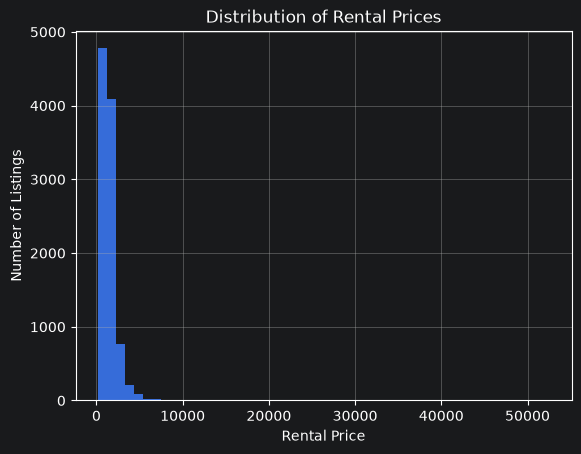

In [10]:
# target distribution
df["price"].hist(bins=50)
plt.xlabel("Rental Price")
plt.ylabel("Number of Listings")
plt.title("Distribution of Rental Prices")
plt.show()


The median advertised price is 1,270, while the mean is approximately 1,486. Prices range from 200 to 52,500.

The distribution is strongly right-skewed:
most listings have lower prices, while a small number of expensive listings extend the upper tail. These extreme values require investigation before modelling.

This summary includes all raw listings. Rental periods will be checked separately to make sure that those prices are monthly.

## 6. Outlier investigation

### 6.1. Price

In [11]:
df.nlargest(10, "price")[
    [
        "id", "price", "price_type", "square_feet",
        "bedrooms", "cityname", "state"
    ]
]

,id,price,price_type,square_feet,bedrooms,cityname,state
8829,5666447277,52500,Monthly,1418,0.0,Barstow,CA
9996,5668640983,25000,Monthly,8716,6.0,Montecito,CA
9990,5659901599,19500,Monthly,5000,4.0,Los Angeles,CA
9972,5664581587,14950,Monthly,4044,6.0,Los Angeles,CA
8581,5508735725,13500,Monthly,1325,2.0,Los Angeles,CA
9825,5508686302,13000,Monthly,2530,3.0,Los Angeles,CA
8573,5668636698,11000,Monthly,1322,2.0,Coronado,CA
9946,5650235118,11000,Monthly,3395,5.0,Hollywood,FL
9997,5668643292,11000,Monthly,11318,6.0,Potomac,MD
9227,5508879959,10600,Monthly,1636,2.0,Los Angeles,CA


In [12]:
highest_price_listing = df.loc[df["price"].idxmax()]

print("Recorded price:", highest_price_listing["price"])
print("Title:", highest_price_listing["title"])
print("Description:")
print(highest_price_listing["body"])

Recorded price: 52500
Title: Studio apartment for rent
Description:
Barstow It's 14/18ft. studio apartment furnished include utilities, television, Internet hook up nice big deck. $500.00/ month $350.00 deposit. 1st month$450.00. A-c, Alarm, Balcony, Deck, Patio or Porch, Cable Ready, Microwave, Oversized Closets, Paid Utilities, Highspeed internet Available


The highest recorded price is 52,500, but its description mentions 500 dollars per month. This inconsistency suggests a possible recording error.

The record is flagged for a cleaning decision. It is not automatically corrected because the description does not independently confirm the true price.

Conclusion: high prices should not be removed simply because they are unusual, investigate other high prices

In [14]:
print("Rental periods:")
print(df["price_type"].value_counts(dropna=False))

Rental periods:
price_type
Monthly           9998
Weekly               1
Monthly|Weekly       1
Name: count, dtype: int64


In [15]:
df.loc[
    df["price_type"] != "Monthly",
    ["id", "price", "price_type", "currency", "title"]
]

,id,price,price_type,currency,title
15,5659276240,1560,Weekly,USD,Studio Cottage 214
235,5625835116,275,Monthly|Weekly,USD,A-P-T Suites Lakeland - Low Weekly & Monthly R...


There are 9,998 Monthly listings, one Weekly listing and one Monthly|Weekly listing.

The two listings that are not unambiguously monthly could be excluded during preprocessing so the target consistently represents monthly rent.

### 6.2. Property size

In [16]:
df.nlargest(5, "square_feet")[
    ["id", "square_feet", "bedrooms", "bathrooms", "price"]
]

,id,square_feet,bedrooms,bathrooms,price
9998,5668662559,40000,1.0,NaN,4790
9997,5668643292,11318,6.0,8.5,11000
9996,5668640983,8716,6.0,8.0,25000
9995,5630240092,6300,5.0,4.0,6000
9994,5664597657,5921,6.0,4.0,3000


The largest recorded property size is 40,000 square feet for a one-bedroom listing. This unusual combination suggests a possible recording error, but it does not prove that the value is incorrect.

Conclusion: further investigation needed here

# Main issues to investigate

Before modelling, the suspicious price of $52,500 and property size of 40,000 square feet need further investigation to determine whether they are recording errors or genuine values.

Missing values need appropriate handling, for example in amenities, where missing information should not automatically mean no amenities.

The two listings with non-monthly or ambiguous rental periods also need to be addressed so the target consistently represents monthly rent.

Finally, `price_display` should be excluded because it reveals the target price and would introduce data leakage.